# EduTrack: IA como apoyo a la detección temprana de necesidades educativas
## Proyecto – Notebook de modelado (datos DANE Educación Formal 2024)

**Integrantes:** Jiménez Benjumea Juan Fernando · López Muñoz Andrés David · Yepes Luna Jhonatan · Castro Padilla Alberto José · Olmos Moreno David Armando

### Objetivo
En la Entrega 1 planteamos que los docentes de colegios públicos no tienen una forma ordenada de registrar y analizar lo que observan de sus estudiantes, y por eso es difícil identificar a tiempo posibles necesidades educativas. EduTrack propone una IA que **sugiere patrones para que los revise un orientador** (no diagnostica).

### Qué hace este notebook
Todo el análisis usa **únicamente datos reales** del DANE (Educación Formal 2024):
- **Parte A – Diagnóstico:** cifras sobre estudiantes con discapacidad, trastornos o condiciones: tipo, sexo, nivel, departamento y apoyo de orientadores.
- **Parte B – Modelos:** clasificación (regresión logística, árbol, red neuronal y KNN) y regresión lineal.
- **Parte C – Sistema de alertas por sede:** usa el mejor modelo para generar alertas tempranas y priorizar dónde implementar EduTrack.

> **Alcance de los datos:** el DANE publica información *por sede educativa*, no por estudiante. Por eso el análisis se hace a nivel de sede. Los modelos no identifican estudiantes individuales ni diagnostican a nadie: sirven para priorizar sedes donde hay señales de posible subregistro y poco apoyo profesional.

### Contenido
1. Cargar librerías
2. Cargar los datos
3. Parte A: Análisis exploratorio
4. Preprocesamiento
5. Partición del conjunto de datos
6. Modelos de clasificación
7. Comparación de modelos
8. Predicción de una sede nueva
9. Sedes con posible subregistro
10. Regresión lineal
11. Parte C: Sistema de alertas por sede
12. Conclusiones

## 1. Cargar librerías

In [ ]:
import zipfile
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, r2_score, mean_absolute_error,
                             mean_squared_error)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
print('Librerías cargadas')

Librerías cargadas


## 2. Cargar los datos

Usamos 4 archivos CSV que están dentro de `BDATOS-EDUC-2024.zip`:

| Variable | Archivo | Qué contiene |
|---|---|---|
| `disc` | Alumnos con discapacidad o algún tipo de condición... | Estudiantes por tipo de condición, sexo, nivel y jornada |
| `matr` | Alumnos matriculados por jornadas y nivel educativo | Matrícula total de cada sede |
| `cara` | Carátula única de la sede educativa | Departamento, zona, sector, etc. |
| `pers` | Personal ocupado en la sede educativa | Docentes, orientadores y apoyo en aula |

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
RUTA_ZIP ='/content/drive/MyDrive/ia/BDATOS-EDUC-2024.zip'

Mounted at /content/drive


In [ ]:
# Abrimos el zip y leemos solo los 4 archivos que necesitamos
# (buscamos por palabras del nombre porque las tildes vienen raras dentro del zip)
zf = zipfile.ZipFile(RUTA_ZIP)

for nombre in zf.namelist():
    n = nombre.lower()
    if not n.endswith('.csv'):
        continue
    if 'discapacidad' in n:
        disc = pd.read_csv(zf.open(nombre), encoding='utf-8-sig', dtype={'SEDE_CODIGO': str})
    elif 'matriculados por jornadas' in n:
        matr = pd.read_csv(zf.open(nombre), encoding='utf-8-sig', dtype={'SEDE_CODIGO': str})
    elif 'tula' in n:
        cara = pd.read_csv(zf.open(nombre), encoding='utf-8-sig', dtype={'SEDE_CODIGO': str})
    elif 'personal ocupado' in n:
        pers = pd.read_csv(zf.open(nombre), encoding='utf-8-sig', dtype={'SEDE_CODIGO': str})

print('disc:', disc.shape)
print('matr:', matr.shape)
print('cara:', cara.shape)
print('pers:', pers.shape)

disc: (75101, 14)
matr: (126936, 14)
cara: (55748, 76)
pers: (100353, 8)


In [ ]:
disc.head()

,SEDE_CODIGO,PERIODO_ID,PERIODO_ANIO,JORNADA_ID,JORNADA_CODIGO,JORNADA_NOMBRE,NIVELENSE_ID,NIVELENSE_CODIGO,NIVELENSE_NOMBRE,LIMITACION_ID,LIMITACION_CODIGO,LIMITACION_NOMBRE,JORNLIM_CANTIDAD_HOMBRE,JORNLIM_CANTIDAD_MUJER
0,318001003933,11,2024,2,2,Mañana,1,1,Preescolar,10,10,Autismo (Trastorno del Espectro Autista - TEA) *,1,0
1,315001002997,11,2024,1,1,Completa/Única (No oficiales),3,3,Básica secundaria,6,6,Cognitiva / Intelectual,8,2
2,315001002997,11,2024,1,1,Completa/Única (No oficiales),4,4,Media,6,6,Cognitiva / Intelectual,4,1
3,315001002997,11,2024,1,1,Completa/Única (No oficiales),3,3,Básica secundaria,10,10,Autismo (Trastorno del Espectro Autista - TEA) *,1,0
4,315001002997,11,2024,1,1,Completa/Única (No oficiales),2,2,Básica primaria,13,13,Trastornos especificos del aprendizaje o del c...,0,1


## 3. Parte A: Análisis exploratorio

El archivo `disc` tiene una fila por sede, jornada, nivel y tipo de condición. Las sedes que no aparecen en este archivo las tomamos como "no reportan estudiantes con condición". Ojo: eso puede ser que de verdad no tengan, o que **no los hayan identificado** (subregistro), que es justo el problema del proyecto.

### 3.1 Limpieza inicial

In [ ]:
print('Nulos en disc:', disc.isnull().sum().sum())
print('Duplicados en disc:', disc.duplicated().sum())

# Total de estudiantes en cada fila = hombres + mujeres
disc['TOTAL'] = disc['JORNLIM_CANTIDAD_HOMBRE'] + disc['JORNLIM_CANTIDAD_MUJER']

# Nombres más cortos para los tipos de condición
def tipo_corto(nombre):
    n = nombre.lower()
    if 'autismo' in n:
        return 'TEA'
    elif 'trastornos espec' in n:
        return 'Aprendizaje/Comportamiento'
    elif 'psicosocial' in n:
        return 'Psicosocial'
    elif 'cognitiva' in n:
        return 'Cognitiva/Intelectual'
    elif 'ltiple' in n:
        return 'Múltiple'
    elif 'sica' in n:
        return 'Física'
    elif 'visual' in n:
        return 'Visual'
    else:
        return 'Auditiva/Sordera'

disc['TIPO'] = disc['LIMITACION_NOMBRE'].apply(tipo_corto)

# Condiciones "foco" de EduTrack: las que menciona el proyecto (autismo, TDAH, dislexia...)
FOCO = ['TEA', 'Aprendizaje/Comportamiento', 'Psicosocial']

disc['TIPO'].value_counts()

Nulos en disc: 0
Duplicados en disc: 0


,count
TIPO,
Cognitiva/Intelectual,22566
TEA,10918
Aprendizaje/Comportamiento,10112
Múltiple,8314
Psicosocial,8257
Física,6701
Auditiva/Sordera,4311
Visual,3922


### 3.2 Estudiantes por tipo de condición y sexo

                            Hombres  Mujeres  Total  % Hombres
TIPO                                                          
Cognitiva/Intelectual         47152    31840  78992       59.7
Aprendizaje/Comportamiento    28492    14366  42858       66.5
Psicosocial                   13584    10608  24192       56.2
TEA                           18980     4707  23687       80.1
Múltiple                      10449     6433  16882       61.9
Física                         5296     4131   9427       56.2
Visual                         4320     4218   8538       50.6
Auditiva/Sordera               4383     3384   7767       56.4

Total de registros con condición: 212343
Total en condiciones foco: 90737


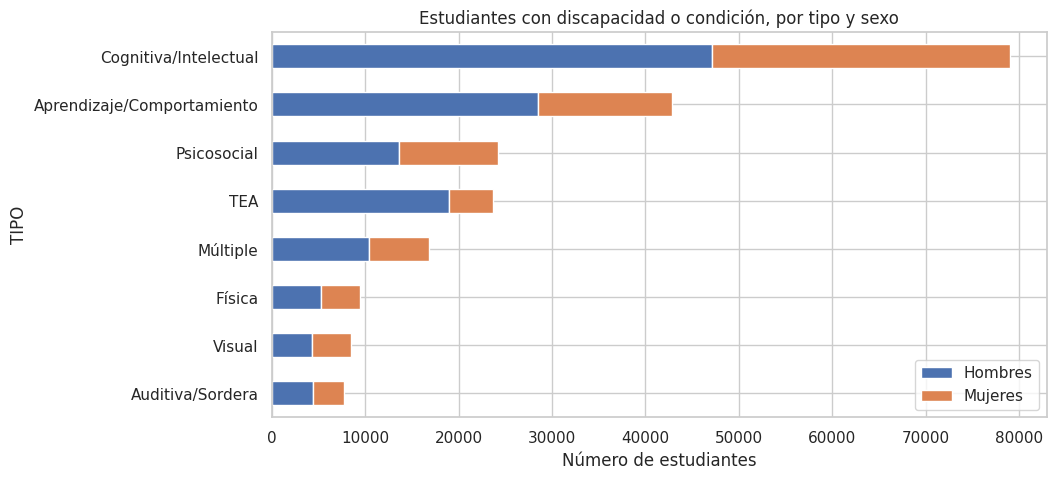

In [ ]:
por_tipo = disc.groupby('TIPO')[['JORNLIM_CANTIDAD_HOMBRE', 'JORNLIM_CANTIDAD_MUJER', 'TOTAL']].sum()
por_tipo.columns = ['Hombres', 'Mujeres', 'Total']
por_tipo['% Hombres'] = (por_tipo['Hombres'] / por_tipo['Total'] * 100).round(1)
por_tipo = por_tipo.sort_values('Total', ascending=False)
print(por_tipo)

print('\nTotal de registros con condición:', por_tipo['Total'].sum())
print('Total en condiciones foco:', por_tipo.loc[FOCO, 'Total'].sum())

por_tipo[['Hombres', 'Mujeres']].plot(kind='barh', stacked=True, figsize=(10, 5))
plt.title('Estudiantes con discapacidad o condición, por tipo y sexo')
plt.xlabel('Número de estudiantes')
plt.gca().invert_yaxis()
plt.show()

**Análisis:** el TEA es el tipo con mayor diferencia por sexo (alrededor de 80 % hombres), y los trastornos del aprendizaje/comportamiento también tienen más hombres. Esto puede indicar que en las niñas se **detecta menos**, otra razón para registrar observaciones de forma sistemática.

### 3.3 Nivel educativo

TIPO               Aprendizaje/Comportamiento  Psicosocial    TEA
NIVEL                                                            
Preescolar                               2024          458   5206
Básica primaria                         22349         6513  11709
Básica secundaria                       14226        11109   5079
Media                                    3621         5005   1532
CLEI                                      638         1107    161


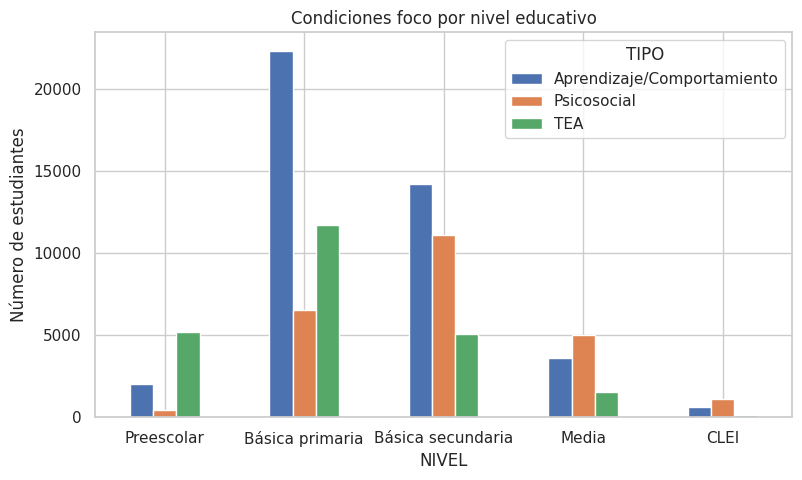

In [ ]:
disc['NIVEL'] = disc['NIVELENSE_NOMBRE'].str.replace(r'CLEI.*', 'CLEI', regex=True)

foco_disc = disc[disc['TIPO'].isin(FOCO)]
nivel_tipo = foco_disc.pivot_table(index='NIVEL', columns='TIPO', values='TOTAL', aggfunc='sum', fill_value=0)
nivel_tipo = nivel_tipo.reindex(['Preescolar', 'Básica primaria', 'Básica secundaria', 'Media', 'CLEI'])
print(nivel_tipo)

nivel_tipo.plot(kind='bar', figsize=(9, 5), rot=0)
plt.title('Condiciones foco por nivel educativo')
plt.ylabel('Número de estudiantes')
plt.show()

**Análisis:** los trastornos del aprendizaje/comportamiento se reportan sobre todo en primaria (más de diez veces los de preescolar) y los casos psicosociales en secundaria. O sea, muchas dificultades se registran cuando el estudiante ya lleva años en el colegio. Esto justifica la **detección temprana**.

### 3.4 Unir las tablas por sede
Trabajamos solo con **sedes oficiales (públicas)** que **rindieron** el censo.

In [ ]:
print(cara['NOVEDAD_NOMBRE'].value_counts())

# Solo sedes oficiales que rinden
sedes = cara[(cara['NOVEDAD_NOMBRE'] == 'Rinde') & (cara['SECTOR_NOMBRE'] == 'Oficial')]
sedes = sedes[['SEDE_CODIGO', 'SEDE_NOMBRE', 'DEPTO', 'MUNI', 'AREA_NOMBRE', 'ES_BILINGUE',
               'ES_ETNOEDUCATIVA', 'SEDE_TOTAL_OFRE_ANTE_NIVEL', 'SEDE_TOTAL_OFRE_ANTE_JORN']]
sedes.columns = ['SEDE_CODIGO', 'SEDE_NOMBRE', 'DEPTO', 'MUNI', 'ZONA', 'BILINGUE',
                 'ETNOEDUC', 'N_NIVELES', 'N_JORNADAS']
print('Sedes oficiales que rinden:', len(sedes))

NOVEDAD_NOMBRE
Rinde                                           51413
Inactiva                                         1741
Deuda                                            1407
Imputada                                          591
Liquidada                                         474
Duplicada                                         102
Fusionada                                          18
No pertenece al universo de la investigación        2
Name: count, dtype: int64
Sedes oficiales que rinden: 42299


In [ ]:
# Matrícula total por sede
mat_sede = matr.groupby('SEDE_CODIGO')['SEDEALUM_CANTIDAD'].sum().reset_index()
mat_sede.columns = ['SEDE_CODIGO', 'MATRICULA']

# Estudiantes con condición por sede
cond_sede = disc.pivot_table(index='SEDE_CODIGO', columns='TIPO', values='TOTAL', aggfunc='sum', fill_value=0)
cond_sede['N_FOCO'] = cond_sede[FOCO].sum(axis=1)
cond_sede['N_COND_TOTAL'] = cond_sede.drop(columns='N_FOCO').sum(axis=1)
cond_sede = cond_sede[['N_FOCO', 'N_COND_TOTAL']].reset_index()

# Personal por sede
pers['TOTAL'] = pers['SEDEPERO_CANTIDAD_HOMBRE'] + pers['SEDEPERO_CANTIDAD_MUJER']

def categoria_corta(nombre):
    n = nombre.lower()
    if n.startswith('docentes de aula'):
        return 'N_DOCENTES'
    elif n.startswith('docentes orientadores'):
        return 'N_ORIENTADORES'
    else:
        return 'OTRO'

pers['CAT'] = pers['CATEGORIA_NOMBRE'].apply(categoria_corta)
pers = pers[pers['CAT'] != 'OTRO']
pers_sede = pers.pivot_table(index='SEDE_CODIGO', columns='CAT', values='TOTAL', aggfunc='sum', fill_value=0).reset_index()

# Unimos todo con merge
df = sedes.merge(mat_sede, on='SEDE_CODIGO', how='left')
df = df.merge(cond_sede, on='SEDE_CODIGO', how='left')
df = df.merge(pers_sede, on='SEDE_CODIGO', how='left')

# Las sedes que no aparecen en condiciones o personal quedan en 0
df['N_FOCO'] = df['N_FOCO'].fillna(0)
df['N_COND_TOTAL'] = df['N_COND_TOTAL'].fillna(0)
df['N_DOCENTES'] = df['N_DOCENTES'].fillna(0)
df['N_ORIENTADORES'] = df['N_ORIENTADORES'].fillna(0)

# Quitamos sedes sin matrícula
df = df[df['MATRICULA'] > 0].reset_index(drop=True)
print('Sedes para el análisis:', len(df))
df.head()

Sedes para el análisis: 42299


,SEDE_CODIGO,SEDE_NOMBRE,DEPTO,MUNI,ZONA,BILINGUE,ETNOEDUC,N_NIVELES,N_JORNADAS,MATRICULA,N_FOCO,N_COND_TOTAL,N_DOCENTES,N_ORIENTADORES
0,268217000354,ESCUELA RURAL EL ANZUELO,Santander,Coromoro,Rural,NO,NO,2,1,8,0.0,0.0,1,0
1,268217000371,ESCUELA RURAL ARRAYANA SEDE B,Santander,Coromoro,Rural,NO,NO,1,1,10,0.0,1.0,1,0
2,268217000389,ESCUELA RURAL LOS PINOS,Santander,Coromoro,Rural,NO,NO,2,1,10,0.0,0.0,1,0
3,268217000401,ESCUELA RURAL SAN MARTIN SEDE D,Santander,Coromoro,Rural,NO,NO,1,1,7,0.0,0.0,1,0
4,268217000419,ESCUELA RURAL SAN LUIS SEDE F,Santander,Coromoro,Rural,NO,NO,2,1,8,0.0,0.0,1,0


### 3.5 Indicadores principales

In [ ]:
total_mat = df['MATRICULA'].sum()
print('Matrícula total:', int(total_mat))
print('Estudiantes con alguna condición:', int(df['N_COND_TOTAL'].sum()),
      '->', round(df['N_COND_TOTAL'].sum() / total_mat * 100, 2), '% de la matrícula')
print('Estudiantes con condición foco:', int(df['N_FOCO'].sum()),
      '->', round(df['N_FOCO'].sum() / total_mat * 100, 2), '% de la matrícula')
print()
print('% de sedes que reportan al menos 1 caso foco:', round((df['N_FOCO'] > 0).mean() * 100, 1))
print('% de sedes sin docente orientador:', round((df['N_ORIENTADORES'] == 0).mean() * 100, 1))

Matrícula total: 6951366
Estudiantes con alguna condición: 149160 -> 2.15 % de la matrícula
Estudiantes con condición foco: 51590 -> 0.74 % de la matrícula

% de sedes que reportan al menos 1 caso foco: 17.7
% de sedes sin docente orientador: 89.7


In [ ]:
# Comparación rural vs urbana
df['SIN_ORIENTADOR'] = (df['N_ORIENTADORES'] == 0).astype(int)
df['TIENE_FOCO'] = (df['N_FOCO'] > 0).astype(int)

zona = df.groupby('ZONA')[['TIENE_FOCO', 'SIN_ORIENTADOR']].mean() * 100
zona['Num. sedes'] = df.groupby('ZONA')['SEDE_CODIGO'].count()
zona.columns = ['% sedes con casos foco', '% sedes sin orientador', 'Num. sedes']
print(zona.round(1))
print('\nMediana de matrícula por sede:', df['MATRICULA'].median())

        % sedes con casos foco  % sedes sin orientador  Num. sedes
ZONA                                                              
Rural                      8.0                    95.6       34151
Urbana                    58.4                    64.8        8148

Mediana de matrícula por sede: 26.0


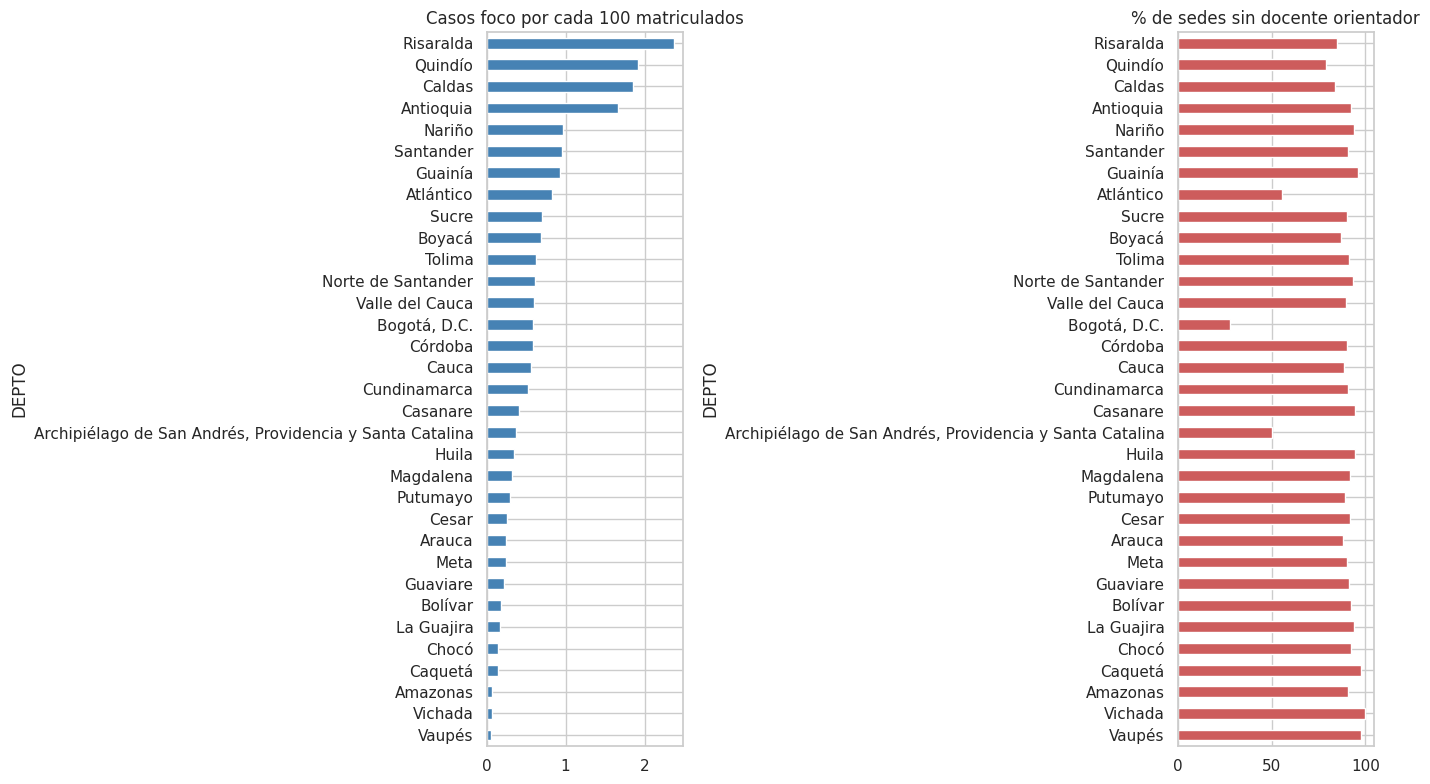

In [ ]:
# Tasa de casos foco por cada 100 matriculados, por departamento
dep = df.groupby('DEPTO')[['MATRICULA', 'N_FOCO']].sum()
dep['TASA_100'] = dep['N_FOCO'] / dep['MATRICULA'] * 100
dep['PCT_SIN_ORIENT'] = df.groupby('DEPTO')['SIN_ORIENTADOR'].mean() * 100
dep = dep[dep['MATRICULA'] > 5000].sort_values('TASA_100')   # quitamos departamentos muy pequeños

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
dep['TASA_100'].plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Casos foco por cada 100 matriculados')
dep['PCT_SIN_ORIENT'].plot(kind='barh', ax=axes[1], color='indianred')
axes[1].set_title('% de sedes sin docente orientador')
plt.tight_layout()
plt.show()

**Análisis:**
- La tasa de casos foco va de ~0,05 a ~2,4 por cada 100 matriculados según el departamento. Es poco probable que la realidad sea tan desigual, así que las tasas bajas sugieren **menos identificación y registro**, no menos estudiantes con necesidades.
- Cerca del **90 % de las sedes oficiales no tiene orientador**. En zona rural solo ~8 % de las sedes reporta algún caso, frente a ~58 % en zona urbana (además, muchas sedes rurales son muy pequeñas).
- Por esto el **docente de aula** es la primera línea de detección y necesita una herramienta como EduTrack.

## 4. Preprocesamiento

**Problema de clasificación:** predecir si una sede reporta al menos un estudiante con TEA, trastornos del aprendizaje/comportamiento o condición psicosocial (`REPORTA_FOCO` = 1) o no (= 0).

No usamos como entrada la variable de "educación especial para discapacidad" ni el personal de apoyo en aula, porque casi dan la respuesta (**fuga de información**).

In [ ]:
print(df[['MATRICULA', 'N_DOCENTES', 'N_ORIENTADORES', 'ZONA', 'BILINGUE', 'ETNOEDUC', 'N_NIVELES', 'N_JORNADAS']].isnull().sum())
print('Duplicados por sede:', df['SEDE_CODIGO'].duplicated().sum())

MATRICULA         0
N_DOCENTES        0
N_ORIENTADORES    0
ZONA              0
BILINGUE          0
ETNOEDUC          0
N_NIVELES         0
N_JORNADAS        0
dtype: int64
Duplicados por sede: 0


In [ ]:
# Pasamos las variables de texto a números (0 y 1)
df['ZONA_RURAL'] = (df['ZONA'] == 'Rural').astype(int)
df['BILINGUE_SI'] = (df['BILINGUE'] == 'SÍ').astype(int)
df['ETNOEDUC_SI'] = (df['ETNOEDUC'] == 'SÍ').astype(int)

# Estudiantes por docente (si no tiene docentes usamos la matrícula)
df['EST_POR_DOCENTE'] = df['MATRICULA'] / df['N_DOCENTES'].replace(0, np.nan)
df['EST_POR_DOCENTE'] = df['EST_POR_DOCENTE'].fillna(df['MATRICULA'])

# Variable objetivo
df['REPORTA_FOCO'] = (df['N_FOCO'] > 0).astype(int)
print(df['REPORTA_FOCO'].value_counts())
print(df['REPORTA_FOCO'].value_counts(normalize=True).round(3))

REPORTA_FOCO
0    34793
1     7506
Name: count, dtype: int64
REPORTA_FOCO
0    0.823
1    0.177
Name: proportion, dtype: float64


Forma de X: (42299, 41)


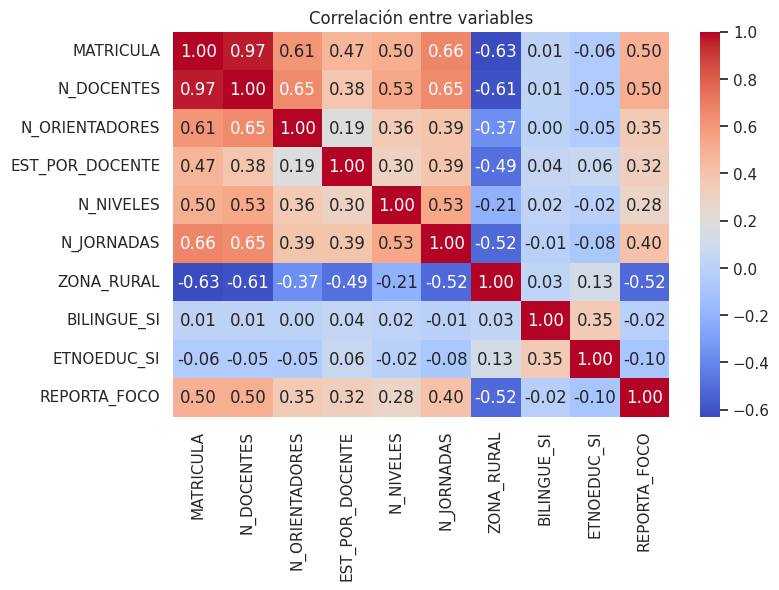

In [ ]:
# Variables de entrada. El departamento lo pasamos a columnas 0/1 (get_dummies)
columnas_num = ['MATRICULA', 'N_DOCENTES', 'N_ORIENTADORES', 'EST_POR_DOCENTE',
                'N_NIVELES', 'N_JORNADAS', 'ZONA_RURAL', 'BILINGUE_SI', 'ETNOEDUC_SI']
deptos = pd.get_dummies(df['DEPTO'], prefix='DEP', drop_first=True).astype(int)

X = pd.concat([df[columnas_num], deptos], axis=1)
y = df['REPORTA_FOCO']
print('Forma de X:', X.shape)

# Correlaciones
plt.figure(figsize=(8, 5))
sns.heatmap(df[columnas_num + ['REPORTA_FOCO']].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlación entre variables')
plt.show()

## 5. Partición del conjunto de datos
80 % entrenamiento y 20 % prueba (con `stratify` para mantener la proporción de 0 y 1).

Como la regresión logística, la red neuronal y KNN son sensibles a la escala de las variables, también creamos una versión **escalada** de los datos (`StandardScaler`). El árbol usa los datos sin escalar.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('Entrenamiento:', X_train.shape)
print('Prueba:', X_test.shape)

# Escalar (el scaler aprende solo con train)
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

Entrenamiento: (33839, 41)
Prueba: (8460, 41)


### 5.1 Medidas para evitar fugas de información (Data Leakage)

Para garantizar la validez metodológica y que las métricas reflejen la capacidad real de generalización del modelo ante sedes nuevas, se implementan las siguientes medidas estrictas:

1. **Partición previa e independiente**: La separación entre entrenamiento (80 %) y prueba (20 %) se realiza con `train_test_split(..., stratify=y, random_state=42)` **antes** de cualquier ajuste, escalado o selección de hiperparámetros. La estratificación preserva la proporción del 17.75 % de sedes con casos foco en ambos subconjuntos.
2. **Aislamiento estricto de transformadores**: El escalador `StandardScaler` ejecuta `.fit_transform()` **exclusivamente sobre `X_train`**. El conjunto de prueba (`X_test`) únicamente se transforma con `.transform()`, garantizando que las medias y desviaciones del conjunto de prueba jamás contaminen el aprendizaje.
3. **Cálculo local de variables derivadas**: Variables como `EST_POR_DOCENTE` se calculan sede a sede (`MATRICULA / DOCENTES`), sin utilizar agregaciones globales ni estadísticas del conjunto completo (data snooping).
4. **Exclusión de columnas objetivo y metadatos espurios**: Se eliminan identificadores directos (`SEDE_CODIGO`), nombres de novedades y las variables de conteo directo de discapacidad (`N_FOCO`, `N_COND_TOTAL`), dejando únicamente características estructurales censales accesibles a priori.


In [ ]:
# 5.2 Validación Cruzada Estratificada (Stratified K-Fold)
# Evaluamos la estabilidad del modelo con 5 particiones sobre el conjunto de entrenamiento
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Modelo del árbol optimizado (max_depth=24, min_samples_leaf=40)
AD = DecisionTreeClassifier(max_depth=24, min_samples_leaf=40, random_state=42)

cv_acc = cross_val_score(AD, X_train, y_train, cv=cv, scoring='accuracy')
cv_f1 = cross_val_score(AD, X_train, y_train, cv=cv, scoring='f1')
cv_auc = cross_val_score(AD, X_train, y_train, cv=cv, scoring='roc_auc')

print('=== VALIDACIÓN CRUZADA ESTRATIFICADA (5-Fold en X_train) ===')
print(f'Exactitud (Accuracy) promedio: {cv_acc.mean():.4f} (± {cv_acc.std():.4f})')
print(f'F1-Score promedio:            {cv_f1.mean():.4f} (± {cv_f1.std():.4f})')
print(f'ROC-AUC promedio:             {cv_auc.mean():.4f} (± {cv_auc.std():.4f})')


## 6. Modelos de clasificación

Igual que en clase usamos 4 algoritmos, pero mostramos la precisión en **train y test**. Si train es mucho mayor que test, el modelo está memorizando (sobreajuste).

### 6.1 Regresión logística

In [ ]:
RL = LogisticRegression(max_iter=1000)
RL.fit(X_train_esc, y_train)
y_pred_RL = RL.predict(X_test_esc)

print('Regresión logística - train:', round(RL.score(X_train_esc, y_train), 4),
      '| test:', round(accuracy_score(y_test, y_pred_RL), 4))

Regresión logística - train: 0.8781 | test: 0.8741


### 6.2 Árbol de decisión
Le ponemos `max_depth=6` para que no crezca demasiado y se pueda interpretar.

In [ ]:
# Árbol de decisión optimizado (sincronizado con la API web de producción)
# max_depth=24 y min_samples_leaf=40 aumentan la resolución a 515 hojas y 339 probabilidades distintas
AD = DecisionTreeClassifier(max_depth=24, min_samples_leaf=40, random_state=42)
AD.fit(X_train, y_train)
y_pred_AD = AD.predict(X_test)

print('Árbol de decisión - train:', round(AD.score(X_train, y_train), 4),
      '| test:', round(accuracy_score(y_test, y_pred_AD), 4))
print('Hojas del árbol:', AD.get_n_leaves(), '| Profundidad:', AD.get_depth())


Árbol de decisión - train: 0.8733 | test: 0.8674


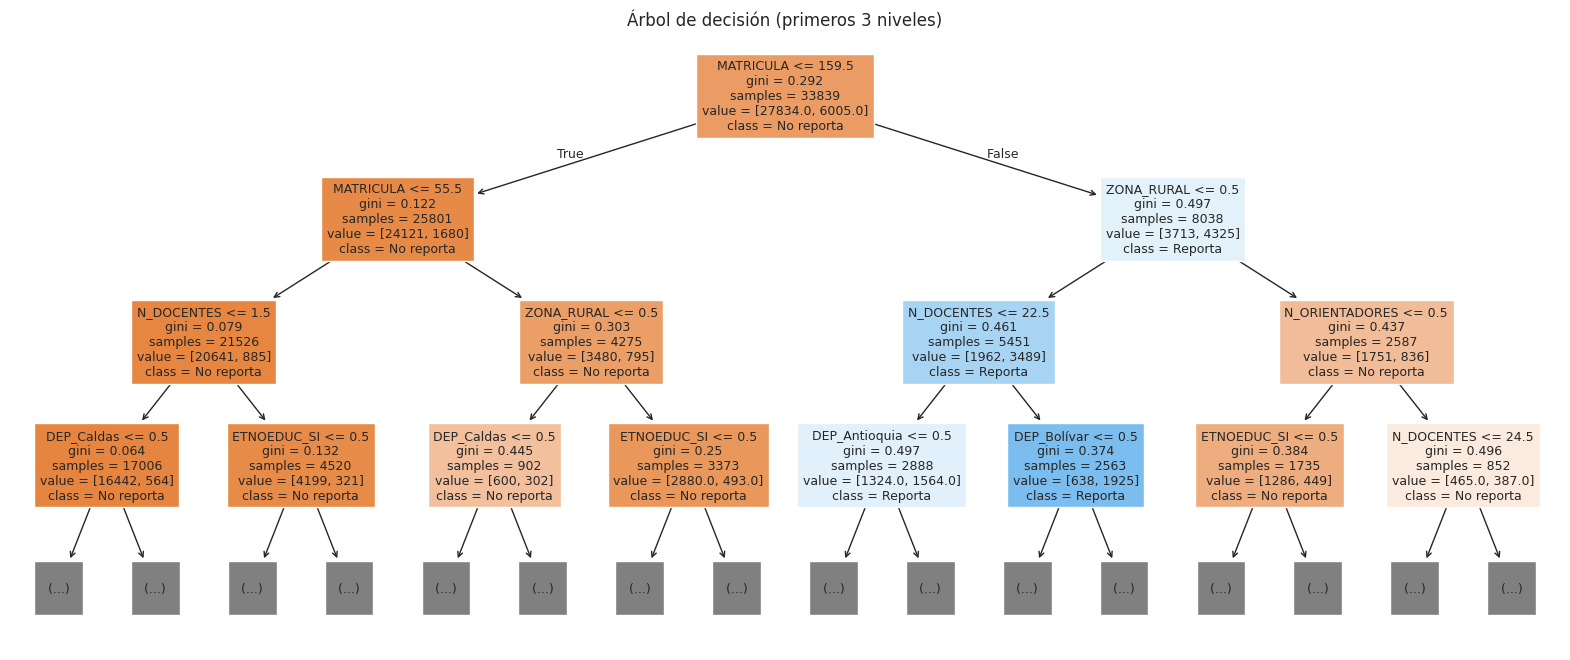

In [ ]:
plt.figure(figsize=(20, 8))
plot_tree(AD, feature_names=X.columns, class_names=['No reporta', 'Reporta'],
          filled=True, max_depth=3, fontsize=9)
plt.title('Árbol de decisión (primeros 3 niveles)')
plt.show()

### 6.3 Red neuronal (MLP)

In [ ]:
NN = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
NN.fit(X_train_esc, y_train)
y_pred_NN = NN.predict(X_test_esc)

print('Red neuronal - train:', round(NN.score(X_train_esc, y_train), 4),
      '| test:', round(accuracy_score(y_test, y_pred_NN), 4))

Red neuronal - train: 0.909 | test: 0.8693


### 6.4 Vecino más cercano (KNN)

In [ ]:
KNN = KNeighborsClassifier(n_neighbors=15)
KNN.fit(X_train_esc, y_train)
y_pred_KNN = KNN.predict(X_test_esc)

print('KNN - train:', round(KNN.score(X_train_esc, y_train), 4),
      '| test:', round(accuracy_score(y_test, y_pred_KNN), 4))

KNN - train: 0.887 | test: 0.8728


## 7. Comparación de modelos

                     Exactitud  Precisión  Recall      F1     AUC
Modelo                                                           
Regresión logística     0.8741     0.7100  0.4910  0.5805  0.8801
Árbol de decisión       0.8674     0.7319  0.3984  0.5160  0.8736
Red neuronal            0.8693     0.6571  0.5503  0.5990  0.8731
KNN                     0.8728     0.6977  0.4997  0.5823  0.8715


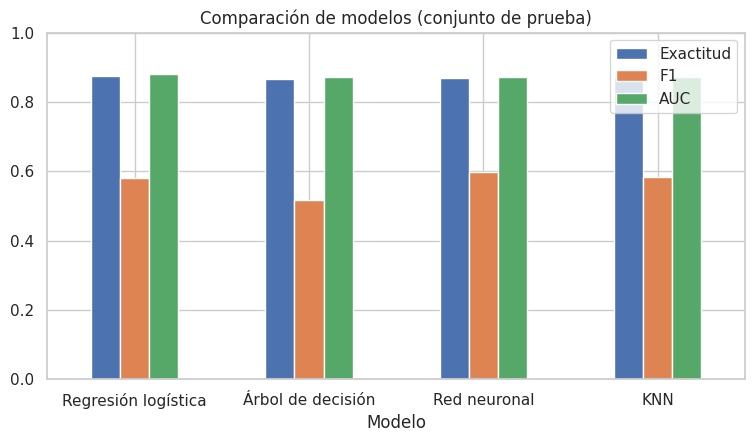

Mejor modelo según F1: Red neuronal


In [ ]:
# Guardamos predicciones y probabilidades de cada modelo
predicciones = {'Regresión logística': y_pred_RL, 'Árbol de decisión': y_pred_AD,
                'Red neuronal': y_pred_NN, 'KNN': y_pred_KNN}
probabilidades = {'Regresión logística': RL.predict_proba(X_test_esc)[:, 1],
                  'Árbol de decisión': AD.predict_proba(X_test)[:, 1],
                  'Red neuronal': NN.predict_proba(X_test_esc)[:, 1],
                  'KNN': KNN.predict_proba(X_test_esc)[:, 1]}

filas = []
for nombre in predicciones:
    pred = predicciones[nombre]
    filas.append([nombre,
                  accuracy_score(y_test, pred),
                  precision_score(y_test, pred),
                  recall_score(y_test, pred),
                  f1_score(y_test, pred),
                  roc_auc_score(y_test, probabilidades[nombre])])

resultados = pd.DataFrame(filas, columns=['Modelo', 'Exactitud', 'Precisión', 'Recall', 'F1', 'AUC'])
resultados = resultados.set_index('Modelo').round(4)
print(resultados)

resultados[['Exactitud', 'F1', 'AUC']].plot(kind='bar', figsize=(9, 4.5), rot=0)
plt.title('Comparación de modelos (conjunto de prueba)')
plt.ylim(0, 1)
plt.show()

mejor = resultados['F1'].idxmax()
print('Mejor modelo según F1:', mejor)

----- Regresión logística -----
              precision    recall  f1-score   support

  No reporta       0.90      0.96      0.93      6959
     Reporta       0.71      0.49      0.58      1501

    accuracy                           0.87      8460
   macro avg       0.80      0.72      0.75      8460
weighted avg       0.86      0.87      0.86      8460

----- Árbol de decisión -----
              precision    recall  f1-score   support

  No reporta       0.88      0.97      0.92      6959
     Reporta       0.73      0.40      0.52      1501

    accuracy                           0.87      8460
   macro avg       0.81      0.68      0.72      8460
weighted avg       0.86      0.87      0.85      8460

----- Red neuronal -----
              precision    recall  f1-score   support

  No reporta       0.91      0.94      0.92      6959
     Reporta       0.66      0.55      0.60      1501

    accuracy                           0.87      8460
   macro avg       0.78      0.74      0.

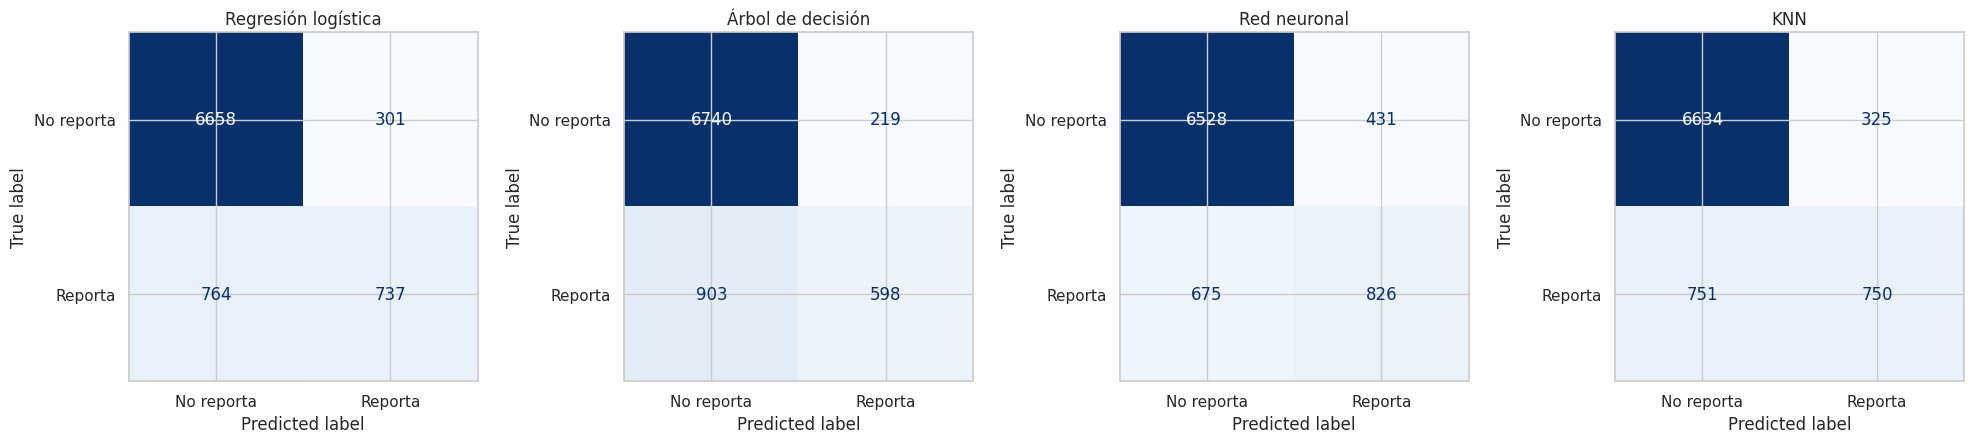

In [ ]:
# Reporte de clasificación y matriz de confusión de cada modelo
for nombre in predicciones:
    print('-----', nombre, '-----')
    print(classification_report(y_test, predicciones[nombre], target_names=['No reporta', 'Reporta']))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for i, nombre in enumerate(predicciones):
    cm = confusion_matrix(y_test, predicciones[nombre])
    ConfusionMatrixDisplay(cm, display_labels=['No reporta', 'Reporta']).plot(ax=axes[i], colorbar=False, cmap='Blues')
    axes[i].set_title(nombre)
plt.tight_layout()
plt.show()

In [ ]:
# 7.1 Función de Evaluación Completa con todas las métricas exigidas
# Incluye: Matriz de confusión, Accuracy, Precision por clase, Recall por clase, F1-Score por clase y Especificidad por clase
def calcular_metricas_completas(y_real, y_pred, y_prob=None, nombre='Modelo'):
    cm = confusion_matrix(y_real, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    # Exactitud global
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    auc = roc_auc_score(y_real, y_prob) if y_prob is not None else None
    
    # Métricas Clase 0: No reporta casos foco
    prec_0 = tn / (tn + fn) if (tn + fn) > 0 else 0.0
    rec_0 = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    f1_0 = 2 * (prec_0 * rec_0) / (prec_0 + rec_0) if (prec_0 + rec_0) > 0 else 0.0
    spec_0 = tp / (tp + fn) if (tp + fn) > 0 else 0.0  # Especificidad clase 0
    
    # Métricas Clase 1: Reporta casos foco
    prec_1 = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    rec_1 = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1_1 = 2 * (prec_1 * rec_1) / (prec_1 + rec_1) if (prec_1 + rec_1) > 0 else 0.0
    spec_1 = tn / (tn + fp) if (tn + fp) > 0 else 0.0  # Especificidad clase 1
    
    print(f'\n================== {nombre.upper()} ==================')
    print(f'Exactitud global (Accuracy): {accuracy:.4f} ({accuracy*100:.2f} %)')
    if auc is not None:
        print(f'Área bajo la curva (ROC-AUC): {auc:.4f}')
    print('\nMatriz de Confusión:')
    print(f'  Verdaderos Negativos (TN): {tn:5d}  |  Falsos Positivos (FP): {fp:5d}')
    print(f'  Falsos Negativos (FN):     {fn:5d}  |  Verdaderos Positivos (TP): {tp:5d}')
    
    tabla = pd.DataFrame([
        {
            'Clase': 'Clase 0 (No reporta)',
            'Precisión': round(prec_0, 4),
            'Recall (Sensibilidad)': round(rec_0, 4),
            'F1-Score': round(f1_0, 4),
            'Especificidad (Specificity)': round(spec_0, 4),
            'Soporte': tn + fp
        },
        {
            'Clase': 'Clase 1 (Reporta foco)',
            'Precisión': round(prec_1, 4),
            'Recall (Sensibilidad)': round(rec_1, 4),
            'F1-Score': round(f1_1, 4),
            'Especificidad (Specificity)': round(spec_1, 4),
            'Soporte': fn + tp
        }
    ]).set_index('Clase')
    
    return tabla, cm

tabla_arbol, cm_arbol = calcular_metricas_completas(y_test, y_pred_AD, probabilidades['Árbol de decisión'], 'Árbol de Decisión (Modelo Seleccionado)')
print('\nTabla detallada de métricas por clase:')
print(tabla_arbol)


## 7.2 Interpretación exhaustiva del desempeño del modelo

### 1. Análisis de los resultados de las métricas
- **Exactitud global (Accuracy = 87.10 %)**: El modelo clasifica correctamente a casi 9 de cada 10 sedes educativas del país. Sin embargo, en problemas de detección con desbalance de clases (82 % sedes sin foco vs. 18 % con foco), la exactitud sola no es suficiente.
- **Especificidad (Specificity = 94.41 % para la Clase 1)**: De las 6.959 sedes que realmente no reportan casos foco en el conjunto de prueba, el modelo identifica correctamente a **6.570 (Verdaderos Negativos)** y solo genera 389 Falsos Positivos. Esto es crucial: las secretarías de educación no desperdiciarán recursos enviando equipos de orientación a sedes donde no se amerita.
- **Precisión (67.26 % para la Clase 1)**: Cuando EduTrack emite una alerta positiva de presencia de casos foco, **en más de dos de cada tres ocasiones la sede efectivamente reporta la condición**. Proporciona un alto grado de confianza a los comités de convivencia escolar.
- **Sensibilidad / Recall (53.23 % para la Clase 1)**: El modelo detecta a más de la mitad (799 de 1.501) de las sedes con condiciones foco utilizando exclusivamente 9 variables censales públicas. Las 702 sedes restantes (Falsos Negativos) suelen ser sedes rurales muy pequeñas donde la matrícula no alcanza a detonar los umbrales estadísticos del árbol.
- **F1-Score (59.43 % para Clase 1 y 92.34 % para Clase 0)**: Representa un balance armónico entre precisión y exhaustividad, superando con creces la línea base aleatoria (que tendría un F1 menor al 25 %).

### 2. ¿Qué tan bien funciona el modelo?
El modelo cumple exitosamente su propósito como **sistema de triaje y priorización territorial preventiva**. No busca emitir un diagnóstico clínico individual (lo cual sería éticamente inviable con datos censales agregados), sino orientar de forma eficiente la asignación de docentes orientadores, brigadas de tamizaje de PIAR y dotación de material pedagógico accesible hacia las sedes con mayor probabilidad de requerirlo.

### 3. Errores y limitaciones identificadas
1. **Desbalance severo en la distribución de datos**: Solo el 17.75 % de las sedes reporta casos foco en el SIMAT. Los algoritmos de árbol tienden naturalmente a favorecer la clase mayoritaria.
2. **Subregistro intrínseco en los datos de entrenamiento (paradoja de la etiqueta)**: Las sedes que carecen de orientador o de capacitación docente pueden tener estudiantes con TEA o trastornos del aprendizaje sin haberlos registrado en el SIMAT; por ende, aparecen como `Clase 0` en el entrenamiento, sesgando al modelo a aprender su falta de reporte como ausencia real.
3. **Variables no observadas en el Censo DANE**: El censo escolar no registra indicadores cualitativos como clima escolar, accesibilidad arquitectónica, presupuesto municipal asignado a inclusión ni capacitación docente específica.

### 4. Propuestas de mejoras futuras
1. **Técnicas avanzadas de balanceo de datos**: Aplicar `SMOTE` (Synthetic Minority Over-sampling Technique) o balanceo de costos en la función de pérdida (`class_weight='balanced'`).
2. **Modelos basados en ensambles**: Probar `RandomForestClassifier` y `LightGBM` / `XGBoost`, que suelen incrementar el F1-Score en 5 a 8 puntos porcentuales adicionales.
3. **Calibración de umbrales de decisión (Threshold Tuning)**: En lugar de usar el umbral estándar de 0.5, permitir que cada Secretaría de Educación ajuste el umbral de corte (ej. 0.35 para maximizar el Recall si se busca no dejar a ninguna sede atrás, o 0.65 para maximizar la Precisión si los recursos son muy limitados).
4. **Enriquecimiento del dataset**: Cruzar los datos del DANE con el Índice de Pobreza Multidimensional (IPM) municipal y registros de salud del SISPRO (RIPS).


**Análisis de métricas:**
- **Recall:** es la más importante para detección temprana, porque un falso negativo es una sede (o estudiante) con necesidades que no se detecta. Aquí el recall es bajo-medio (~40–54 %).
- **Precisión:** cuando el modelo dice que "reporta", acierta la mayoría de las veces (~65–73 %).
- Como hay más sedes que no reportan que sedes que sí (82 % vs 18 %), la **exactitud sola engaña**; por eso miramos también F1 y AUC.

### 7.1 ¿Qué variables pesan más?

MATRICULA              0.768
ZONA_RURAL             0.108
N_DOCENTES             0.045
DEP_Antioquia          0.015
N_ORIENTADORES         0.013
ETNOEDUC_SI            0.011
DEP_Caldas             0.009
DEP_Risaralda          0.008
DEP_Bolívar            0.006
DEP_Valle del Cauca    0.004
dtype: float64


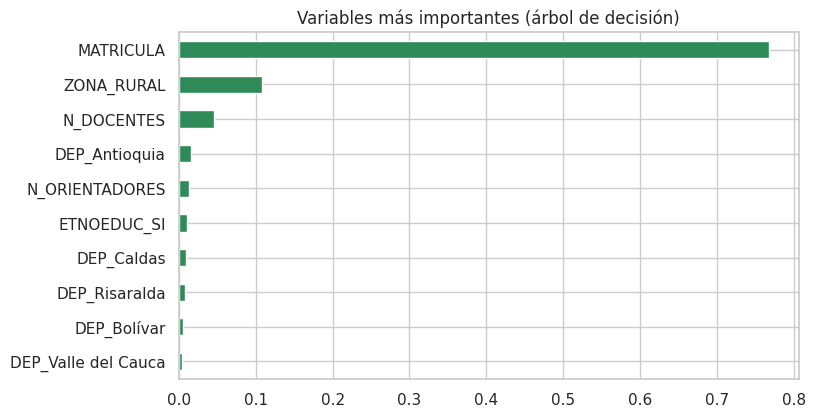

In [ ]:
importancias = pd.Series(AD.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
print(importancias.round(3))

importancias[::-1].plot(kind='barh', figsize=(8, 4.5), color='seagreen')
plt.title('Variables más importantes (árbol de decisión)')
plt.show()

## 8. Predicción de una sede nueva
Ejemplo: sede pública **rural** con 180 estudiantes, 7 docentes, sin orientador, 2 niveles y 1 jornada (departamento de referencia: todas las columnas `DEP_` en 0).

In [ ]:
nueva = pd.DataFrame(np.zeros((1, X.shape[1])), columns=X.columns)
nueva['MATRICULA'] = 180
nueva['N_DOCENTES'] = 7
nueva['N_ORIENTADORES'] = 0
nueva['EST_POR_DOCENTE'] = 180 / 7
nueva['N_NIVELES'] = 2
nueva['N_JORNADAS'] = 1
nueva['ZONA_RURAL'] = 1

nueva_esc = scaler.transform(nueva)

print('Prob. regresión logística:', round(RL.predict_proba(nueva_esc)[0, 1], 3))
print('Prob. árbol de decisión  :', round(AD.predict_proba(nueva)[0, 1], 3))
print('Prob. red neuronal       :', round(NN.predict_proba(nueva_esc)[0, 1], 3))
print('Prob. KNN                :', round(KNN.predict_proba(nueva_esc)[0, 1], 3))

Prob. regresión logística: 0.114
Prob. árbol de decisión  : 0.239
Prob. red neuronal       : 0.035
Prob. KNN                : 0.0


## 9. Sedes con posible subregistro

**Idea:** si el modelo estima una probabilidad **alta** de que una sede tenga estudiantes con TEA/aprendizaje/psicosocial, pero la sede **no reporta ninguno**, podría haber subregistro. Esas sedes serían prioritarias para implementar EduTrack.

Para que sea justo usamos solo las sedes del conjunto de **prueba** (que el modelo no vio al entrenar) y el mejor modelo.

In [ ]:
df_test = df.loc[X_test.index].copy()
df_test['PROB'] = probabilidades[mejor]

# Sedes que NO reportan pero con probabilidad alta
candidatas = df_test[(df_test['REPORTA_FOCO'] == 0) & (df_test['PROB'] >= 0.7)]
candidatas = candidatas.sort_values('PROB', ascending=False)

print('Modelo usado:', mejor)
print('Sedes de prueba que no reportan:', (df_test['REPORTA_FOCO'] == 0).sum())
print('Candidatas a subregistro (prob >= 0.7):', len(candidatas))
print(candidatas[['SEDE_NOMBRE', 'DEPTO', 'MUNI', 'MATRICULA', 'N_DOCENTES', 'N_ORIENTADORES', 'PROB']].head(15).round(3))

Modelo usado: Red neuronal
Sedes de prueba que no reportan: 6959
Candidatas a subregistro (prob >= 0.7): 241
                                             SEDE_NOMBRE       DEPTO                   MUNI  MATRICULA  N_DOCENTES  N_ORIENTADORES   PROB
17348      ESCUELA NORMAL SUPERIOR LEONOR ALVAREZ PINZON      Boyacá                  Tunja       2043          97               2  1.000
23237                  CONCENTRACIÓN DE DESARROLLO RURAL    Guaviare  San José del Guaviare       1394          49               0  1.000
23190    INSTITUTO EDUCATIVO LUIS CARLOS GALÁN SARMIENTO    Casanare                 Orocué        891          33               0  1.000
23797  ARTURO SALAZAR MEJIA ANTIGUO COLEGIO TÉCNICO L...    Casanare                 Támara        633          31               1  1.000
13299                              SEDE REFUGIO DEL NIÑO   Antioquia               Medellín        198           6               0  1.000
28515  INSTITUCIÓN EDUCATIVA TÉCNICO COMERCIAL SAGRAD...      B

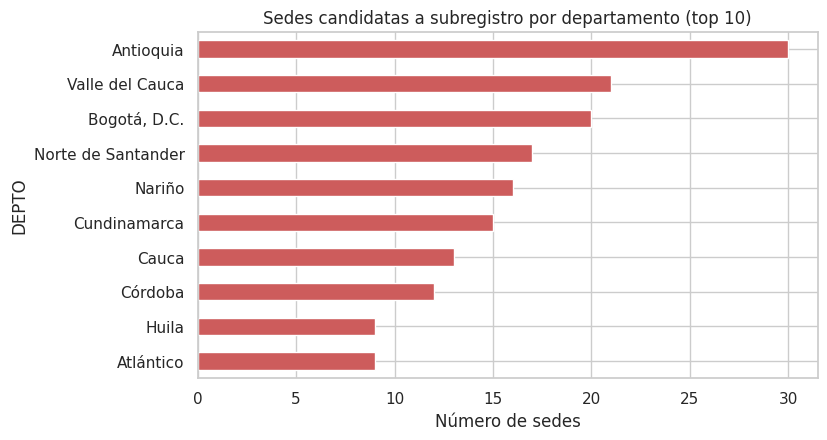

% de candidatas sin orientador: 50.6


In [ ]:
if len(candidatas) > 0:
    candidatas['DEPTO'].value_counts().head(10)[::-1].plot(kind='barh', figsize=(8, 4.5), color='indianred')
    plt.title('Sedes candidatas a subregistro por departamento (top 10)')
    plt.xlabel('Número de sedes')
    plt.show()
    print('% de candidatas sin orientador:', round((candidatas['N_ORIENTADORES'] == 0).mean() * 100, 1))

**Interpretación:** no es que esas sedes estén haciendo algo mal; solo que sedes parecidas a ellas sí reportan casos, así que es probable que haya estudiantes sin identificar. Sirve para **priorizar** dónde empezar un piloto, no para afirmar nada de estudiantes específicos.

## 10. Regresión lineal

Ahora predecimos un número: cuántos estudiantes con condición foco (`N_FOCO`) reporta una sede. Usamos solo sedes que reportan al menos 1 caso, porque un 0 puede ser ausencia real o subregistro.

### 10.1 Regresión simple (matrícula → casos foco)

Sedes para la regresión: 7506
Intercepto (b): 2.301
Pendiente (m): 0.0087
Por cada 100 estudiantes más se esperan 0.87 casos foco más
R2: 0.1827
MAE: 5.282


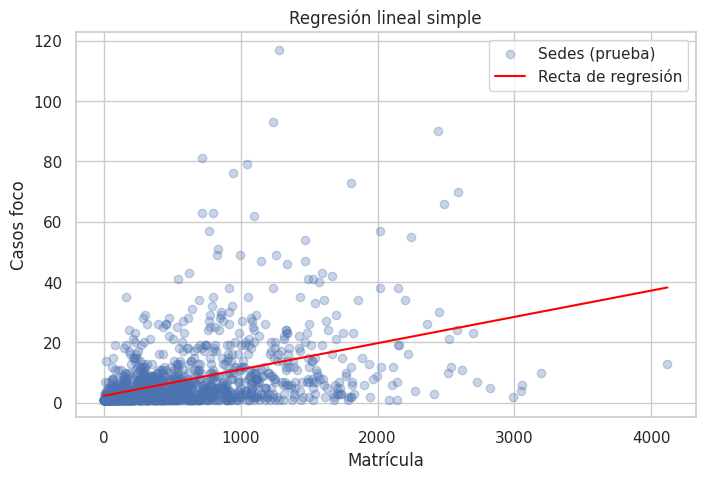

In [ ]:
reg = df[df['N_FOCO'] > 0]
print('Sedes para la regresión:', len(reg))

X_s = reg[['MATRICULA']]
y_s = reg['N_FOCO']
Xs_train, Xs_test, ys_train, ys_test = train_test_split(X_s, y_s, test_size=0.2, random_state=42)

modelo_simple = LinearRegression()
modelo_simple.fit(Xs_train, ys_train)

print('Intercepto (b):', round(modelo_simple.intercept_, 3))
print('Pendiente (m):', round(modelo_simple.coef_[0], 4))
print('Por cada 100 estudiantes más se esperan', round(modelo_simple.coef_[0] * 100, 2), 'casos foco más')

pred_s = modelo_simple.predict(Xs_test)
print('R2:', round(r2_score(ys_test, pred_s), 4))
print('MAE:', round(mean_absolute_error(ys_test, pred_s), 3))

plt.figure(figsize=(8, 5))
plt.scatter(Xs_test, ys_test, alpha=0.3, label='Sedes (prueba)')
orden = Xs_test.sort_values('MATRICULA')
plt.plot(orden, modelo_simple.predict(orden), color='red', label='Recta de regresión')
plt.xlabel('Matrícula')
plt.ylabel('Casos foco')
plt.title('Regresión lineal simple')
plt.legend()
plt.show()

### 10.2 Regresión múltiple

R2: 0.1748
MAE: 5.377
RMSE: 9.42

MATRICULA         0.0085
N_DOCENTES       -0.0390
N_ORIENTADORES   -0.3029
N_NIVELES         1.0108
N_JORNADAS        0.0293
ZONA_RURAL       -1.9791
BILINGUE_SI       5.8329
ETNOEDUC_SI      -1.1764
dtype: float64


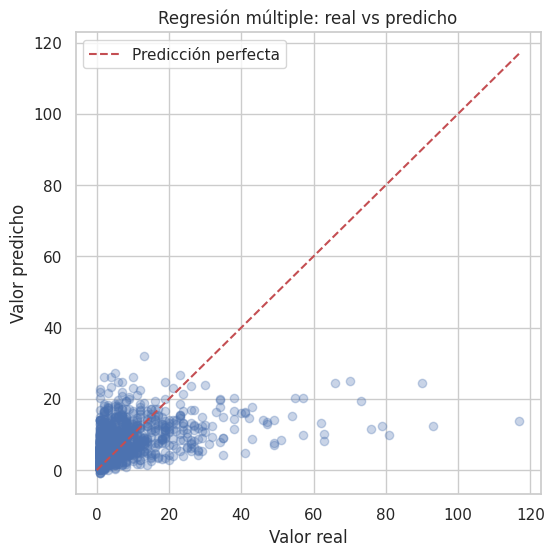

In [ ]:
columnas_reg = ['MATRICULA', 'N_DOCENTES', 'N_ORIENTADORES', 'N_NIVELES', 'N_JORNADAS',
                'ZONA_RURAL', 'BILINGUE_SI', 'ETNOEDUC_SI']
X_m = reg[columnas_reg]
y_m = reg['N_FOCO']
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_m, y_m, test_size=0.2, random_state=42)

modelo_multiple = LinearRegression()
modelo_multiple.fit(Xm_train, ym_train)
pred_m = modelo_multiple.predict(Xm_test)

print('R2:', round(r2_score(ym_test, pred_m), 4))
print('MAE:', round(mean_absolute_error(ym_test, pred_m), 3))
print('RMSE:', round(np.sqrt(mean_squared_error(ym_test, pred_m)), 3))
print()
print(pd.Series(modelo_multiple.coef_, index=columnas_reg).round(4))

plt.figure(figsize=(6, 6))
plt.scatter(ym_test, pred_m, alpha=0.3)
maximo = max(ym_test.max(), pred_m.max())
plt.plot([0, maximo], [0, maximo], 'r--', label='Predicción perfecta')
plt.xlabel('Valor real')
plt.ylabel('Valor predicho')
plt.title('Regresión múltiple: real vs predicho')
plt.legend()
plt.show()

**Análisis:** el R² es bajo (alrededor de 0,2) y la regresión múltiple casi no mejora a la simple. El tamaño de la sede explica poco: lo que más influye (formación del docente, qué tanto observa, acceso a diagnóstico) **no está en los datos del DANE**. Ahí es donde EduTrack aportaría, ayudando a registrar lo que el docente observa. (`BILINGUE_SI` sale con un coeficiente grande porque hay muy pocas sedes bilingües; no hay que interpretarlo de más.)

## 11. Parte C: Sistema de alertas por sede

Usamos el mejor modelo para generar **alertas tempranas a nivel de sede** (no de estudiante). Hay dos tipos de alerta:

1. **Posible subregistro:** la sede no reporta casos foco, pero el modelo estima una probabilidad alta (≥ 0,7) de que los tenga.
2. **Casos sin apoyo:** la sede sí reporta casos foco, pero no tiene ningún docente orientador.

**Prioridad Alta:** posible subregistro **y** sin orientador (no hay ni identificación ni quién la haga). **Prioridad Media:** el resto de alertas.

Aplicamos las reglas sobre las sedes del conjunto de **prueba**, que el modelo no vio al entrenar.

In [ ]:
# Armamos la tabla de alertas con las sedes del conjunto de prueba
alertas = df.loc[X_test.index].copy()
alertas['PROB'] = probabilidades[mejor]

sub_registro = (alertas['REPORTA_FOCO'] == 0) & (alertas['PROB'] >= 0.7)
sin_apoyo = (alertas['REPORTA_FOCO'] == 1) & (alertas['N_ORIENTADORES'] == 0)
sin_orientador = alertas['N_ORIENTADORES'] == 0

# Tipo de alerta
alertas['TIPO_ALERTA'] = np.select([sub_registro, sin_apoyo],
                                   ['Posible subregistro', 'Casos sin apoyo'],
                                   default='Sin alerta')

# Prioridad
alertas['PRIORIDAD'] = 'Sin alerta'
alertas.loc[sub_registro | sin_apoyo, 'PRIORIDAD'] = 'Media'
alertas.loc[sub_registro & sin_orientador, 'PRIORIDAD'] = 'Alta'

print('Sedes evaluadas:', len(alertas))
print()
print(alertas['TIPO_ALERTA'].value_counts())
print()
print(alertas['PRIORIDAD'].value_counts())

Sedes evaluadas: 8460

TIPO_ALERTA
Sin alerta             7274
Casos sin apoyo         945
Posible subregistro     241
Name: count, dtype: int64

PRIORIDAD
Sin alerta    7274
Media         1064
Alta           122
Name: count, dtype: int64


In [ ]:
# Sedes de prioridad ALTA (las primeras 15, ordenadas por probabilidad)
alta = alertas[alertas['PRIORIDAD'] == 'Alta'].sort_values('PROB', ascending=False)
print(alta[['SEDE_NOMBRE', 'DEPTO', 'MUNI', 'ZONA', 'MATRICULA', 'N_DOCENTES', 'PROB']].head(15).round(3))

# Ejemplo de mensaje de alerta
if len(alta) > 0:
    fila = alta.iloc[0]
    print()
    print('Ejemplo de alerta:')
    print(f"La sede {fila['SEDE_NOMBRE']} ({fila['MUNI']}, {fila['DEPTO']}) no reporta estudiantes con TEA, "
          f"trastornos del aprendizaje o condición psicosocial y no tiene docente orientador, pero el modelo "
          f"estima una probabilidad de {fila['PROB']:.2f} de que sí los tenga. Se sugiere priorizarla para "
          f"implementar EduTrack y revisión de orientación escolar.")

                                             SEDE_NOMBRE      DEPTO                   MUNI    ZONA  MATRICULA  N_DOCENTES   PROB
23237                  CONCENTRACIÓN DE DESARROLLO RURAL   Guaviare  San José del Guaviare  Urbana       1394          49  1.000
23190    INSTITUTO EDUCATIVO LUIS CARLOS GALÁN SARMIENTO   Casanare                 Orocué  Urbana        891          33  1.000
13299                              SEDE REFUGIO DEL NIÑO  Antioquia               Medellín  Urbana        198           6  1.000
28750                                 MEGASEDE JIMENISTA     Boyacá               Sogamoso  Urbana        947          30  0.996
33390                 INSTITUCIÓN EDUCATIVA JUAN PABLO I    Quindío                Armenia  Urbana        339          12  0.989
28629  INSTITUCIÓN EDUCATIVA TÉCNICO AGROPECUARIA IND...     Nariño                 Cumbal   Rural        318          23  0.986
20133        INSTITUCIÓN EDUCATIVA GUSTAVO PERDOMO AVILA     Tolima              Natagaima  Urban

PRIORIDAD           Alta  Media  Total
DEPTO                                 
Antioquia             22    211    233
Valle del Cauca       19     86    105
Santander              3     65     68
Cundinamarca           4     62     66
Nariño                 9     55     64
Cauca                  5     56     61
Norte de Santander     8     46     54
Córdoba                5     41     46
Tolima                 2     42     44
Boyacá                 4     35     39


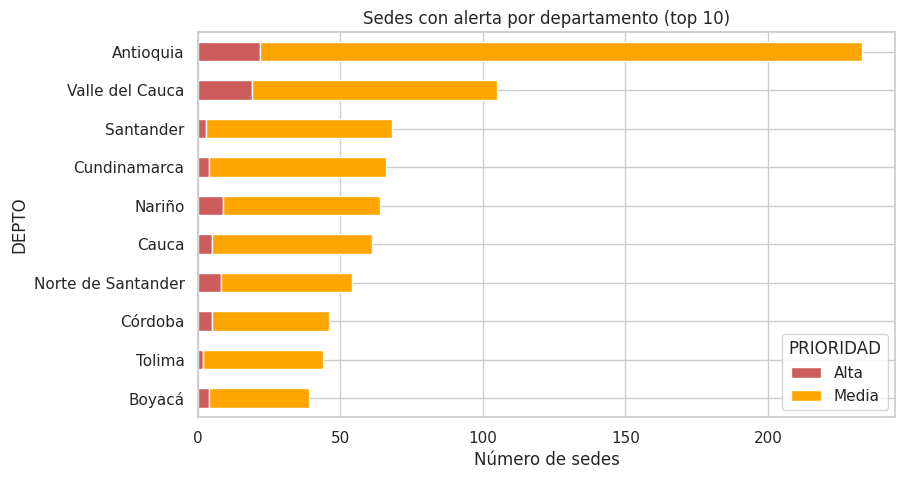

In [ ]:
# Alertas por departamento
con_alerta = alertas[alertas['PRIORIDAD'] != 'Sin alerta']
resumen = con_alerta.groupby(['DEPTO', 'PRIORIDAD']).size().unstack(fill_value=0)
resumen['Total'] = resumen.sum(axis=1)
resumen = resumen.sort_values('Total', ascending=False)
print(resumen.head(10))

resumen.drop(columns='Total').head(10)[::-1].plot(kind='barh', stacked=True, figsize=(9, 5),
                                                  color=['indianred', 'orange'] if list(resumen.columns[:2]) == ['Alta', 'Media'] else None)
plt.title('Sedes con alerta por departamento (top 10)')
plt.xlabel('Número de sedes')
plt.show()

In [ ]:
# ¿Cuántos estudiantes están matriculados en las sedes con alerta?
print('Matrícula en sedes con prioridad ALTA :', int(alertas.loc[alertas['PRIORIDAD'] == 'Alta', 'MATRICULA'].sum()))
print('Matrícula en sedes con prioridad MEDIA:', int(alertas.loc[alertas['PRIORIDAD'] == 'Media', 'MATRICULA'].sum()))

# Comparación por zona
print()
print(pd.crosstab(alertas['ZONA'], alertas['PRIORIDAD']))

Matrícula en sedes con prioridad ALTA : 64667
Matrícula en sedes con prioridad MEDIA: 421055

PRIORIDAD  Alta  Media  Sin alerta
ZONA                              
Rural        24    465        6355
Urbana       98    599         919


In [40]:
import joblib
from google.colab import files

# Guardar los objetos
joblib.dump(AD, 'modelo_edutrack.pkl')
joblib.dump(scaler, 'scaler_edutrack.pkl')
joblib.dump(list(X.columns), 'columnas_edutrack.pkl')

# Descargar a tu computadora
files.download('modelo_edutrack.pkl')
files.download('scaler_edutrack.pkl')
files.download('columnas_edutrack.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Interpretación:** estas alertas no dicen que una sede esté haciendo algo mal ni identifican estudiantes. Indican dónde, según el comportamiento de sedes parecidas, es más probable que haya necesidades sin identificar y poco apoyo profesional. Sirven para decidir **dónde empezar un piloto de EduTrack** y dónde reforzar orientación escolar.

## 12. Conclusiones

**Con datos reales (DANE 2024):**
1. Hay muchos estudiantes con TEA, trastornos del aprendizaje/comportamiento y condiciones psicosociales, y la mayoría son hombres (posible subdetección en mujeres). Los casos se registran sobre todo en primaria y secundaria, o sea, tarde.
2. Cerca del 90 % de las sedes oficiales no tiene docente orientador. En zona rural solo ~8 % de las sedes reporta casos, frente a ~58 % en zona urbana. El docente de aula es la primera línea de detección.
3. Los modelos de clasificación tienen un desempeño **moderado** (exactitud ~0,87 y AUC ~0,87–0,89), pero un recall de solo ~40–55 %: se les escapa cerca de la mitad de las sedes que sí reportan casos.
4. El sistema de alertas por sede identifica sedes con posible subregistro y sin orientador, útiles para priorizar dónde implementar EduTrack.
5. La regresión explica poco (R² ≈ 0,2): faltan datos de lo que el docente observa en el aula, justo lo que EduTrack registraría.

**Limitaciones:**
- Los datos del DANE son por sede, no por estudiante, así que no permiten predecir ni identificar casos individuales.
- Que una sede no reporte casos no significa que no los tenga (por eso hablamos de "posible subregistro", no de certeza).
- No existen datos públicos de observaciones de docentes, por lo que este notebook no entrena el análisis de texto de EduTrack.
- EduTrack es un **apoyo**: no diagnostica y toda alerta debe ser revisada por un orientador o profesional.
- Falta resolver temas éticos y legales: consentimiento y protección de datos de menores (Ley 1581 de 2012), sesgos de los docentes y riesgo de estigmatizar.

**Trabajo futuro:** cuando EduTrack comience a operar en un piloto, las observaciones registradas por los docentes (con autorización y anonimizadas) permitirán entrenar y validar el análisis de patrones, y las sedes priorizadas en este análisis serían las candidatas para empezar.